##  Autoregressive Hidden Markov Model (AR-HMM)

AR-HMM gives every hidden state its own autoregressive equation:

$$Inflation_t=c_{S_t}+\phi_{S_t}Inflation_{t-1}+error_t$$

For two states this means:

$$State\ 0: \quad Inflation_t=c_0+\phi_0 Inflation_{t-1}+error_t$$

$$State\ 1: \quad Inflation_t=c_1+\phi_1 Inflation_{t-1}+error_t$$

The state is unknown, so the final forecast combines both state-specific forecasts using predicted state probabilities.

**one-month-ahead forecast equation**

Before observing inflation in month $t$, the model calculates a forecast under every possible state:

$$Forecast_{t,s}=c_s+\phi_s Inflation_{t-1}$$

It then uses the predicted probability of each state:

$$\widehat{Inflation}_t=\sum_{s=0}^{1}P(S_t=s\mid Information_{t-1})(c_s+\phi_s Inflation_{t-1})$$

In [43]:
# Choose one: 'database' or 'csv'
DATA_SOURCE = 'database'

N_STATES = 2
TEST_START = '2017-01-01'

In [44]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

search_locations = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(path for path in search_locations if (path / 'README.md').exists())
CSV_PATH = PROJECT_ROOT / 'data' / 'processed' / 'US' / 'us_macro_2007_2023.csv'
RESULTS_DIR = PROJECT_ROOT / 'data' / 'processed' / 'model_results'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
AR1_FORECAST_PATH = RESULTS_DIR / 'ar1_forecasts.csv'
AR1_METRICS_PATH = RESULTS_DIR / 'ar1_metrics.json'
HMM_FORECAST_PATH = RESULTS_DIR / 'hmm_forecasts.csv'
HMM_METRICS_PATH = RESULTS_DIR / 'hmm_metrics.json'
ARHMM_FORECAST_PATH = RESULTS_DIR / 'ar_hmm_forecasts.csv'
ARHMM_METRICS_PATH = RESULTS_DIR / 'ar_hmm_metrics.json'
ARHMM_SENTIMENT_FORECAST_PATH = RESULTS_DIR / 'ar_hmm_sentiment_forecasts.csv'
ARHMM_SENTIMENT_METRICS_PATH = RESULTS_DIR / 'ar_hmm_sentiment_metrics.json'
print('Selected source:', DATA_SOURCE)

Selected source: database


**Load US CPI and monthly news sentiment**

In [45]:
if DATA_SOURCE == 'database':
    from sqlalchemy import text

    sys.path.insert(0, str(PROJECT_ROOT))
    from modelling.config import get_sqlalchemy_engine

    engine = get_sqlalchemy_engine()
    query = text("""
        SELECT month_date, cpi_value, avg_monthly_sentiment
        FROM analytics.Monthly_Region_Wide_View
        WHERE region_code = 'US'
        ORDER BY month_date
    """)
    raw = pd.read_sql(query, engine, parse_dates=['month_date'])
    raw = raw.rename(columns={
        'month_date': 'Date',
        'cpi_value': 'CPI',
        'avg_monthly_sentiment': 'News_Sentiment',
    })
else:
    raw = pd.read_csv(
        CSV_PATH,
        usecols=['Date', 'CPIAUCSL', 'News_Sentiment'],
        parse_dates=['Date'],
    ).rename(columns={'CPIAUCSL': 'CPI'})

raw = raw.sort_values('Date').drop_duplicates('Date').set_index('Date')
raw['CPI'] = pd.to_numeric(raw['CPI'], errors='coerce')
raw['News_Sentiment'] = pd.to_numeric(
    raw['News_Sentiment'], errors='coerce'
)
print('Rows:', len(raw))
print('Period:', raw.index.min().date(), 'to', raw.index.max().date())

Rows: 204
Period: 2007-01-01 to 2023-12-01


**Create monthly inflation, its lag, and the fixed split**

In [46]:
data = raw.copy()
data['Inflation_MoM'] = data['CPI'].pct_change(1, fill_method=None) * 100
data['Inflation_Lag1'] = data['Inflation_MoM'].shift(1)
model_data = data[['Inflation_MoM', 'Inflation_Lag1']].dropna().copy()

test_start = pd.Timestamp(TEST_START)
train = model_data.loc[model_data.index < test_start].copy()
test = model_data.loc[model_data.index >= test_start].copy()

if train.empty or test.empty:
    raise ValueError('TEST_START must leave observations in both periods.')

print('Training period:', train.index.min().date(), 'to', train.index.max().date())
print('Training months:', len(train))
print('Test period:    ', test.index.min().date(), 'to', test.index.max().date())
print('Test months:    ', len(test))

Training period: 2007-03-01 to 2016-12-01
Training months: 118
Test period:     2017-01-01 to 2023-12-01
Test months:     84


**Load the saved AR(1) reference**

In [47]:
if not AR1_FORECAST_PATH.exists() or not AR1_METRICS_PATH.exists():
    raise FileNotFoundError(
        'Run 02_AR1_Baseline.ipynb first to create the saved AR(1) results.'
    )

ar1_saved = pd.read_csv(AR1_FORECAST_PATH, parse_dates=['Date']).set_index('Date')
with AR1_METRICS_PATH.open(encoding='utf-8') as file:
    ar1_saved_metrics = json.load(file)

if not test.index.equals(ar1_saved.index):
    raise ValueError('Saved AR(1) dates differ from AR-HMM test dates. Rerun Part 2.')
if not np.allclose(ar1_saved['Actual'], test['Inflation_MoM']):
    raise ValueError('Saved AR(1) actual values differ from this notebook data.')
test['Forecast_AR1'] = ar1_saved['Forecast'].to_numpy()

**Load the saved pure HMM reference**

Part 4 already fitted and forecast the pure HMM. We load those results rather than repeating the model.

In [48]:
if not HMM_FORECAST_PATH.exists() or not HMM_METRICS_PATH.exists():
    raise FileNotFoundError(
        'Run 04_HMM.ipynb first to create the saved HMM results.'
    )

hmm_saved = pd.read_csv(HMM_FORECAST_PATH, parse_dates=['Date']).set_index('Date')
with HMM_METRICS_PATH.open(encoding='utf-8') as file:
    hmm_saved_metrics = json.load(file)

if not test.index.equals(hmm_saved.index):
    raise ValueError('Saved HMM dates differ from AR-HMM test dates. Rerun Part 4.')
if not np.allclose(hmm_saved['Actual'], test['Inflation_MoM']):
    raise ValueError('Saved HMM actual values differ from this notebook data.')
test['Forecast_HMM'] = hmm_saved['Forecast'].to_numpy()

**Fit the AR-HMM on training data**

In [49]:
np.random.seed(42)
arhmm_model = sm.tsa.MarkovRegression(
    train['Inflation_MoM'],
    k_regimes=N_STATES,
    trend='c',
    exog=train[['Inflation_Lag1']],
    switching_exog=True,
    switching_variance=False,
)
arhmm_result = arhmm_model.fit(
    disp=False, maxiter=2000, search_reps=30
)

print('AR-HMM converged:', arhmm_result.mle_retvals.get('converged', False))

c:\Users\zahra\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


AR-HMM converged: True


In [50]:
arhmm_constants = np.array([
    arhmm_result.params[f'const[{state}]'] for state in range(N_STATES)
])
arhmm_phis = np.array([
    arhmm_result.params[f'x1[{state}]'] for state in range(N_STATES)
])
arhmm_variance = max(float(arhmm_result.params['sigma2']), 1e-12)
arhmm_transition = arhmm_result.regime_transition[:, :, 0]

equation_table = pd.DataFrame({
    'Constant (c)': arhmm_constants,
    'Lag coefficient (phi)': arhmm_phis,
}, index=[f'State {state}' for state in range(N_STATES)])
equation_table

,Constant (c),Lag coefficient (phi)
State 0,0.111441,0.404761
State 1,-0.895064,1.031677


In [51]:
for state in range(N_STATES):
    print(
        f'State {state}: Inflation_t = {arhmm_constants[state]:.4f} '
        f'+ {arhmm_phis[state]:.4f} × Inflation_(t-1)'
    )

State 0: Inflation_t = 0.1114 + 0.4048 × Inflation_(t-1)
State 1: Inflation_t = -0.8951 + 1.0317 × Inflation_(t-1)


**AR-HMM transition probabilities**

In [52]:
arhmm_transition_table = pd.DataFrame(
    arhmm_transition.T,
    index=[f'From state {state}' for state in range(N_STATES)],
    columns=[f'To state {state}' for state in range(N_STATES)],
)
arhmm_transition_table.round(3)

,To state 0,To state 1
From state 0,0.986,0.014
From state 1,0.624,0.376


**Produce one-month-ahead AR-HMM forecasts**

In [53]:
arhmm_filtered_probability = (
    arhmm_result.filtered_marginal_probabilities.iloc[-1].to_numpy()
)
arhmm_forecasts = []
arhmm_predicted_probabilities = []

for actual_inflation, lagged_inflation in test[[
    'Inflation_MoM', 'Inflation_Lag1'
]].to_numpy():
    arhmm_predicted_probability = (
        arhmm_transition @ arhmm_filtered_probability
    )
    arhmm_predicted_probabilities.append(arhmm_predicted_probability.copy())

    state_forecasts = arhmm_constants + arhmm_phis * lagged_inflation
    arhmm_forecasts.append(
        float(arhmm_predicted_probability @ state_forecasts)
    )

    arhmm_likelihood = (
        np.exp(
            -0.5 * (actual_inflation - state_forecasts) ** 2
            / arhmm_variance
        )
        / np.sqrt(2 * np.pi * arhmm_variance)
    )
    arhmm_updated = arhmm_predicted_probability * arhmm_likelihood
    if arhmm_updated.sum() > 0:
        arhmm_filtered_probability = arhmm_updated / arhmm_updated.sum()
    else:
        arhmm_filtered_probability = arhmm_predicted_probability

test['Forecast_ARHMM'] = arhmm_forecasts
test[[
    'Inflation_MoM', 'Inflation_Lag1', 'Forecast_ARHMM'
]].head(10)

,Inflation_MoM,Inflation_Lag1,Forecast_ARHMM
Date,,,
2017-01-01,0.404308,0.252452,0.201594
2017-02-01,0.159266,0.404308,0.264410
2017-03-01,-0.046720,0.159266,0.162976
2017-04-01,0.123415,-0.046720,0.077779
2017-05-01,-0.077398,0.123415,0.148218
2017-06-01,0.065163,-0.077398,0.065089
2017-07-01,0.032765,0.065163,0.124122
2017-08-01,0.384863,0.032765,0.110718
2017-09-01,0.510639,0.384863,0.256366


**Compare all three models and save AR-HMM results**

In [54]:
arhmm_errors = test['Inflation_MoM'] - test['Forecast_ARHMM']

# Earlier-model summaries come from their JSON files; only AR-HMM is scored here.
ar1_rmse = float(ar1_saved_metrics['metrics']['rmse'])
ar1_mae = float(ar1_saved_metrics['metrics']['mae'])
ar1_mean_error = float(
    ar1_saved_metrics['metrics']['mean_error_actual_minus_forecast']
)
hmm_rmse = float(hmm_saved_metrics['metrics']['rmse'])
hmm_mae = float(hmm_saved_metrics['metrics']['mae'])
hmm_mean_error = float(
    hmm_saved_metrics['metrics']['mean_error_actual_minus_forecast']
)
arhmm_rmse = np.sqrt(np.mean(arhmm_errors ** 2))
arhmm_mae = np.mean(np.abs(arhmm_errors))
arhmm_mean_error = np.mean(arhmm_errors)

metric_comparison = pd.DataFrame({
    'RMSE': [ar1_rmse, hmm_rmse, arhmm_rmse],
    'MAE': [ar1_mae, hmm_mae, arhmm_mae],
    'Mean Error (Actual - Forecast)': [
        ar1_mean_error, hmm_mean_error, arhmm_mean_error
    ],
}, index=['AR(1)', 'HMM', 'AR-HMM'])
metric_comparison.sort_values('RMSE')

,RMSE,MAE,Mean Error (Actual - Forecast)
AR(1),0.265153,0.195604,0.067525
AR-HMM,0.269457,0.196073,0.074375
HMM,0.331266,0.235046,0.128187


In [55]:
print(f'AR-HMM RMSE improvement over pure HMM: {hmm_rmse - arhmm_rmse:.4f}')
print(f'AR-HMM MAE improvement over pure HMM:  {hmm_mae - arhmm_mae:.4f}')

print(f'AR-HMM change versus AR(1) in RMSE: {ar1_rmse - arhmm_rmse:.4f}')
print(f'AR-HMM change versus AR(1) in MAE:  {ar1_mae - arhmm_mae:.4f}')

arhmm_forecast_output = pd.DataFrame({
    'Date': test.index,
    'Actual': test['Inflation_MoM'].to_numpy(),
    'Forecast': test['Forecast_ARHMM'].to_numpy(),
    'Error': arhmm_errors.to_numpy(),
})
arhmm_forecast_output.to_csv(ARHMM_FORECAST_PATH, index=False)

arhmm_metrics_output = {
    'model': 'AR-HMM',
    'data_source': DATA_SOURCE,
    'target': 'Inflation_MoM',
    'forecast_horizon_months': 1,
    'n_states': int(N_STATES),
    'train_start': str(train.index.min().date()),
    'train_end': str(train.index.max().date()),
    'test_start': str(test.index.min().date()),
    'test_end': str(test.index.max().date()),
    'n_train': int(len(train)),
    'n_test': int(len(test)),
    'parameters': {
        'state_constants': [float(value) for value in arhmm_constants],
        'state_inflation_lag1': [float(value) for value in arhmm_phis],
        'variance': float(arhmm_variance),
        'transition_matrix': arhmm_transition.tolist(),
    },
    'metrics': {
        'rmse': float(arhmm_rmse),
        'mae': float(arhmm_mae),
        'mean_error_actual_minus_forecast': float(arhmm_mean_error),
    },
}
with ARHMM_METRICS_PATH.open('w', encoding='utf-8') as file:
    json.dump(arhmm_metrics_output, file, indent=2)

print('Saved forecasts:', ARHMM_FORECAST_PATH)
print('Saved metrics:  ', ARHMM_METRICS_PATH)

AR-HMM RMSE improvement over pure HMM: 0.0618
AR-HMM MAE improvement over pure HMM:  0.0390
AR-HMM change versus AR(1) in RMSE: -0.0043
AR-HMM change versus AR(1) in MAE:  -0.0005
Saved forecasts: d:\Master Semester 4\Thesis\data\processed\model_results\ar_hmm_forecasts.csv
Saved metrics:   d:\Master Semester 4\Thesis\data\processed\model_results\ar_hmm_metrics.json


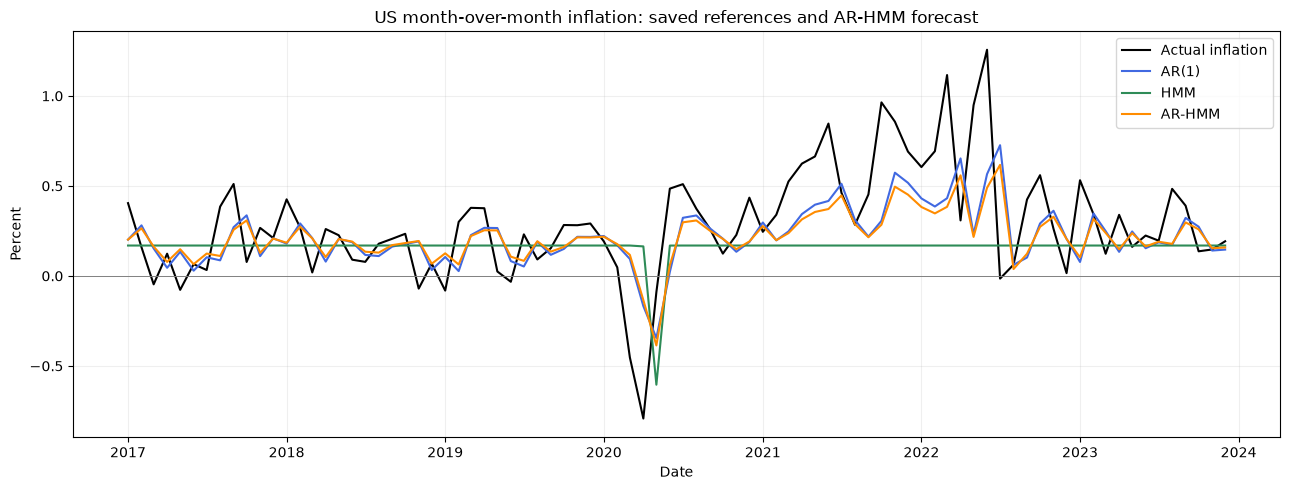

In [56]:
plt.figure(figsize=(13, 5))
plt.plot(test.index, test['Inflation_MoM'], label='Actual inflation', color='black')
plt.plot(test.index, test['Forecast_AR1'], label='AR(1)', color='royalblue')
plt.plot(test.index, test['Forecast_HMM'], label='HMM', color='seagreen')
plt.plot(test.index, test['Forecast_ARHMM'], label='AR-HMM', color='darkorange')
plt.axhline(0, color='gray', linewidth=0.7)
plt.title('US month-over-month inflation: saved references and AR-HMM forecast')
plt.ylabel('Percent')
plt.xlabel('Date')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## Add lagged news sentiment to AR-HMM

The sentiment extension gives every hidden state its own sentiment coefficient:

$$Inflation_t=c_{S_t}+\phi_{S_t}Inflation_{t-1}+\beta_{S_t}Sentiment_{t-1}+error_t$$

In [57]:
sentiment_data = data.copy()
sentiment_data['Sentiment_Lag1'] = sentiment_data['News_Sentiment'].shift(1)

# Missing sentiment stays missing; it is never filled from another month.
sentiment_model_data = sentiment_data[[
    'Inflation_MoM', 'Inflation_Lag1', 'Sentiment_Lag1'
]].dropna().copy()

sentiment_train = sentiment_model_data.loc[
    sentiment_model_data.index < test_start
].copy()
sentiment_test = sentiment_model_data.loc[
    sentiment_model_data.index >= test_start
].copy()

if sentiment_train.empty or sentiment_test.empty:
    raise ValueError('Sentiment must be available in both training and test periods.')

if (not sentiment_train.index.equals(train.index)
        or not sentiment_test.index.equals(test.index)):
    raise ValueError(
        'Lagged sentiment is missing for part of the original AR-HMM sample. '
        'A separate common-sample experiment would be required.'
    )

print('Training period:', sentiment_train.index.min().date(),
      'to', sentiment_train.index.max().date())
print('Training months:', len(sentiment_train))
print('Test period:    ', sentiment_test.index.min().date(),
      'to', sentiment_test.index.max().date())
print('Test months:    ', len(sentiment_test))
print('Sample matches the original AR-HMM: yes')

Training period: 2007-03-01 to 2016-12-01
Training months: 118
Test period:     2017-01-01 to 2023-12-01
Test months:     84
Sample matches the original AR-HMM: yes


**Fit only the new AR-HMM-with-sentiment specification**

In [58]:
# New AR-HMM extension: previous inflation plus previous news sentiment.
np.random.seed(42)
sentiment_arhmm_model = sm.tsa.MarkovRegression(
    sentiment_train['Inflation_MoM'],
    k_regimes=N_STATES,
    trend='c',
    exog=sentiment_train[['Inflation_Lag1', 'Sentiment_Lag1']],
    switching_exog=True,
    switching_variance=False,
)
sentiment_arhmm_result = sentiment_arhmm_model.fit(
    disp=False, maxiter=2500, search_reps=40
)

print('AR-HMM + sentiment converged:',
      sentiment_arhmm_result.mle_retvals.get('converged', False))

c:\Users\zahra\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


AR-HMM + sentiment converged: True


In [59]:
sentiment_constants = np.array([
    sentiment_arhmm_result.params[f'const[{state}]']
    for state in range(N_STATES)
])
sentiment_phis = np.array([
    sentiment_arhmm_result.params[f'x1[{state}]']
    for state in range(N_STATES)
])
sentiment_betas = np.array([
    sentiment_arhmm_result.params[f'x2[{state}]']
    for state in range(N_STATES)
])
sentiment_variance = max(
    float(sentiment_arhmm_result.params['sigma2']), 1e-12
)
sentiment_transition = sentiment_arhmm_result.regime_transition[:, :, 0]

sentiment_equation_table = pd.DataFrame({
    'Constant (c)': sentiment_constants,
    'Inflation lag coefficient (phi)': sentiment_phis,
    'Sentiment lag coefficient (beta)': sentiment_betas,
}, index=[f'State {state}' for state in range(N_STATES)])
sentiment_equation_table

,Constant (c),Inflation lag coefficient (phi),Sentiment lag coefficient (beta)
State 0,2.784356,0.406875,12.664640
State 1,0.158907,0.383394,0.150702


**Produce one-month-ahead forecasts for both common-sample models**

In [60]:
# Reuse the original AR-HMM forecasts already produced above.
sentiment_test['Forecast_ARHMM'] = test['Forecast_ARHMM'].to_numpy()

# Produce forecasts only for the new sentiment model.
sentiment_filtered_probability = (
    sentiment_arhmm_result.filtered_marginal_probabilities.iloc[-1].to_numpy()
)
sentiment_forecasts = []

for actual, lagged_inflation, lagged_sentiment in sentiment_test[[
    'Inflation_MoM', 'Inflation_Lag1', 'Sentiment_Lag1'
]].to_numpy():
    predicted_probability = (
        sentiment_transition @ sentiment_filtered_probability
    )
    state_forecasts = (
        sentiment_constants
        + sentiment_phis * lagged_inflation
        + sentiment_betas * lagged_sentiment
    )
    sentiment_forecasts.append(
        float(predicted_probability @ state_forecasts)
    )

    likelihood = (
        np.exp(
            -0.5 * (actual - state_forecasts) ** 2 / sentiment_variance
        )
        / np.sqrt(2 * np.pi * sentiment_variance)
    )
    updated_probability = predicted_probability * likelihood
    if updated_probability.sum() > 0:
        sentiment_filtered_probability = (
            updated_probability / updated_probability.sum()
        )
    else:
        sentiment_filtered_probability = predicted_probability

sentiment_test['Forecast_ARHMM_Sentiment'] = sentiment_forecasts

sentiment_test[[
    'Inflation_MoM', 'Sentiment_Lag1',
    'Forecast_ARHMM', 'Forecast_ARHMM_Sentiment'
]].head(10)

,Inflation_MoM,Sentiment_Lag1,Forecast_ARHMM,Forecast_ARHMM_Sentiment
Date,,,,
2017-01-01,0.404308,-0.105475,0.201594,0.259526
2017-02-01,0.159266,-0.132172,0.264410,0.308694
2017-03-01,-0.046720,-0.137779,0.162976,0.212764
2017-04-01,0.123415,0.046487,0.077779,0.196033
2017-05-01,-0.077398,-0.385277,0.148218,0.115307
2017-06-01,0.065163,-0.152224,0.065089,0.117060
2017-07-01,0.032765,-0.295361,0.124122,0.123347
2017-08-01,0.384863,-0.298291,0.110718,0.109937
2017-09-01,0.510639,-0.302055,0.256366,0.243780


In [61]:
baseline_errors = (
    sentiment_test['Inflation_MoM']
    - sentiment_test['Forecast_ARHMM']
)
sentiment_errors = (
    sentiment_test['Inflation_MoM']
    - sentiment_test['Forecast_ARHMM_Sentiment']
)

baseline_rmse = np.sqrt(np.mean(baseline_errors ** 2))
baseline_mae = np.mean(np.abs(baseline_errors))
baseline_mean_error = np.mean(baseline_errors)
sentiment_rmse = np.sqrt(np.mean(sentiment_errors ** 2))
sentiment_mae = np.mean(np.abs(sentiment_errors))
sentiment_mean_error = np.mean(sentiment_errors)

sentiment_metric_comparison = pd.DataFrame({
    'RMSE': [baseline_rmse, sentiment_rmse],
    'MAE': [baseline_mae, sentiment_mae],
    'Mean Error (Actual - Forecast)': [
        baseline_mean_error, sentiment_mean_error
    ],
}, index=['Original AR-HMM', 'AR-HMM + lagged sentiment'])

print(f'Sentiment improvement in RMSE: {baseline_rmse - sentiment_rmse:.4f}')
print(f'Sentiment improvement in MAE:  {baseline_mae - sentiment_mae:.4f}')
sentiment_metric_comparison

Sentiment improvement in RMSE: -0.0314
Sentiment improvement in MAE:  -0.0176


,RMSE,MAE,Mean Error (Actual - Forecast)
Original AR-HMM,0.269457,0.196073,0.074375
AR-HMM + lagged sentiment,0.300815,0.213690,0.088730


**Save AR-HMM-with-sentiment results**

In [62]:
sentiment_forecast_output = pd.DataFrame({
    'Date': sentiment_test.index,
    'Actual': sentiment_test['Inflation_MoM'].to_numpy(),
    'Forecast': sentiment_test['Forecast_ARHMM_Sentiment'].to_numpy(),
    'Error': sentiment_errors.to_numpy(),
})
sentiment_forecast_output.to_csv(
    ARHMM_SENTIMENT_FORECAST_PATH, index=False
)

sentiment_metrics_output = {
    'model': 'AR-HMM with lagged sentiment',
    'data_source': DATA_SOURCE,
    'target': 'Inflation_MoM',
    'forecast_horizon_months': 1,
    'n_states': int(N_STATES),
    'train_start': str(sentiment_train.index.min().date()),
    'train_end': str(sentiment_train.index.max().date()),
    'test_start': str(sentiment_test.index.min().date()),
    'test_end': str(sentiment_test.index.max().date()),
    'n_train': int(len(sentiment_train)),
    'n_test': int(len(sentiment_test)),
    'parameters': {
        'state_constants': [float(value) for value in sentiment_constants],
        'state_inflation_lag1': [float(value) for value in sentiment_phis],
        'state_sentiment_lag1': [float(value) for value in sentiment_betas],
        'variance': float(sentiment_variance),
        'transition_matrix': sentiment_transition.tolist(),
    },
    'metrics': {
        'rmse': float(sentiment_rmse),
        'mae': float(sentiment_mae),
        'mean_error_actual_minus_forecast': float(sentiment_mean_error),
    },
    'original_arhmm_reference_metrics': {
        'rmse': float(baseline_rmse),
        'mae': float(baseline_mae),
        'mean_error_actual_minus_forecast': float(baseline_mean_error),
    },
    'improvement_positive_means_sentiment_helped': {
        'rmse': float(baseline_rmse - sentiment_rmse),
        'mae': float(baseline_mae - sentiment_mae),
    },
}
with ARHMM_SENTIMENT_METRICS_PATH.open('w', encoding='utf-8') as file:
    json.dump(sentiment_metrics_output, file, indent=2)

if (not ARHMM_SENTIMENT_FORECAST_PATH.exists()
        or not ARHMM_SENTIMENT_METRICS_PATH.exists()):
    raise RuntimeError('AR-HMM sentiment result files were not created.')

print('Saved forecasts:', ARHMM_SENTIMENT_FORECAST_PATH)
print('Saved metrics:  ', ARHMM_SENTIMENT_METRICS_PATH)

Saved forecasts: d:\Master Semester 4\Thesis\data\processed\model_results\ar_hmm_sentiment_forecasts.csv
Saved metrics:   d:\Master Semester 4\Thesis\data\processed\model_results\ar_hmm_sentiment_metrics.json


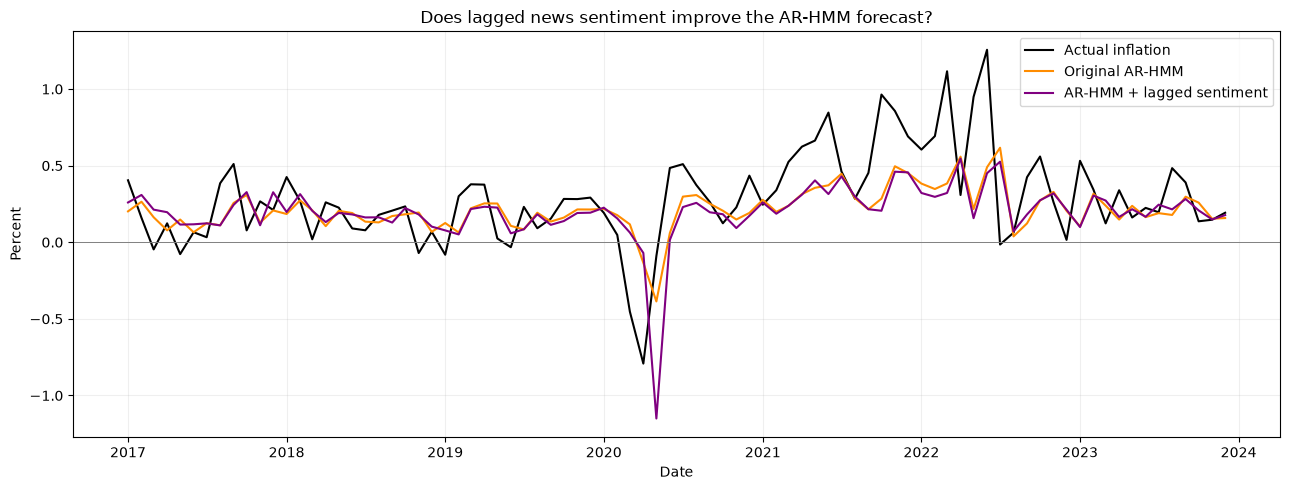

In [63]:
plt.figure(figsize=(13, 5))
plt.plot(sentiment_test.index, sentiment_test['Inflation_MoM'],
         label='Actual inflation', color='black')
plt.plot(sentiment_test.index, sentiment_test['Forecast_ARHMM'],
         label='Original AR-HMM', color='darkorange')
plt.plot(sentiment_test.index, sentiment_test['Forecast_ARHMM_Sentiment'],
         label='AR-HMM + lagged sentiment', color='purple')
plt.axhline(0, color='gray', linewidth=0.7)
plt.title('Does lagged news sentiment improve the AR-HMM forecast?')
plt.ylabel('Percent')
plt.xlabel('Date')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()